# From Reviews to Insights: Sentiment Modelling for Indonesian Mobile Banking Reviews

Three-class sentiment (negative / neutral / positive) for Google Play reviews of BRImo, myBCA, Livin' by Mandiri and wondr by BNI. This notebook follows the data pipeline notebook and starts from `train_pool.csv` and `test.csv`.

| Stage | Purpose |
|---|---|
| 1. Data | Load the labeled files and print integrity checks |
| 2. Utilities | Metrics and group bootstrap |
| 3. Baseline | TF-IDF + logistic regression, learning curve |
| 4. IndoBERT cross-validation | Fine-tuning on the predefined folds for text versions A, B and C |
| 5. Comparison | Out-of-fold metrics with confidence intervals, label audit |
| 6. Test evaluation | One-time evaluation of the chosen run on the held-out test set |
| 7. Continued pretraining | Masked-language-model adaptation on unlabeled reviews |
| 8. Population prediction | Fold-ensemble predictions for every review |

**Design principles**

- Folds come from the data pipeline (`StratifiedGroupKFold`, identical texts never cross folds), so every model sees the same splits.
- Comparisons use out-of-fold predictions pooled over all five folds. The test set is evaluated only in Stage 6.
- Text versions: `A` is `text_raw`, `B` is `text_norm` (light normalization), `C` is `text_norm_slang` (plus abbreviation dictionary).
- Confidence intervals resample whole text groups, so repeated texts do not make the estimates look tighter than they are.
- The number of epochs is read from the per-epoch out-of-fold curves; the test set plays no role in that choice.

## 0. Setup

In [1]:
# %pip install -q transformers

In [1]:
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import FeatureUnion, Pipeline
from transformers import (
    AutoModelForMaskedLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorForLanguageModeling,
    get_linear_schedule_with_warmup,
)

In [66]:
SEED = 42
LABEL_NAMES = {0: "negative", 1: "neutral", 2: "positive"}
N_CLASSES = len(LABEL_NAMES)

# ---- fine-tuning
MODEL_NAME = "indobenchmark/indobert-base-p1"
MAX_LENGTH = 128
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 64
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EPOCHS = 4
SELECTED_EPOCH = EPOCHS            # epoch (1-based) whose predictions are compared
CLASS_WEIGHT_POWER = 0.5           # 0 = unweighted, 1 = fully balanced
SEEDS = [42, 43, 44]
SAVE_MODELS_FOR = ["B"]               # run tags whose fold models are saved to models/

BERT_RUNS = {"B": {"text_col": "text_norm", "model": MODEL_NAME}}

# ---- baseline and evaluation
TEXT_VERSIONS = {"A": "text_raw", "B": "text_norm", "C": "text_norm_slang"}
LR_C_GRID = [1, 3, 10]
N_BOOT = 1000
LEARNING_CURVE_FRACTIONS = [0.25, 0.5, 0.75, 1.0]
LEARNING_CURVE_REPEATS = 3
LEARNING_CURVE_BERT = False
AUDIT_MIN_CONFIDENCE = 0.85

# ---- final evaluation
FINAL_RUN = "BERT_B"

# ---- continued pretraining
RUN_DAPT = False
DAPT_EPOCHS = 2
DAPT_BATCH_SIZE = 32
DAPT_LEARNING_RATE = 5e-5
DAPT_MLM_PROBABILITY = 0.15
DAPT_MAX_LENGTH = 128

MOUNT_DRIVE = True

In [40]:
IN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("mbanking_sentiment")
if IN_COLAB and MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/mbanking_sentiment")

PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"
MODEL_DIR = BASE_DIR / "models"
for folder in (RESULTS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "no GPU")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Tesla T4


## 1. Data

The integrity checks print `FLAG` lines for anything that would weaken the comparisons: missing text, invalid labels, texts that cross folds, and thin cells in the label counts.

In [41]:
READ_KWARGS = dict(encoding="utf-8-sig", parse_dates=["review_date"],
                   dtype={"review_created_version": str, "app_version": str})
train_pool = pd.read_csv(PROCESSED_DIR / "train_pool.csv", **READ_KWARGS).reset_index(drop=True)
test_set = pd.read_csv(PROCESSED_DIR / "test.csv", **READ_KWARGS).reset_index(drop=True)
N_FOLDS = int(train_pool["fold"].nunique())

flags = []
text_columns = list(TEXT_VERSIONS.values())
for name, frame in (("train_pool", train_pool), ("test", test_set)):
    for column in text_columns:
        n_missing = int(frame[column].isna().sum() + frame[column].astype(str).str.strip().eq("").sum())
        if n_missing:
            flags.append(f"{name}: {n_missing} rows with empty {column}")
    if not frame["label_id"].isin(list(LABEL_NAMES)).all():
        flags.append(f"{name}: label_id outside {list(LABEL_NAMES)}")

crossing = int((train_pool.groupby("text_key")["fold"].nunique() > 1).sum())
if crossing:
    flags.append(f"{crossing} texts appear in more than one fold")
if set(train_pool["review_id"]) & set(test_set["review_id"]):
    flags.append("review_id shared between training pool and test set")

fold_counts = pd.crosstab(train_pool["fold"], train_pool["label_id"].map(LABEL_NAMES))
if (fold_counts.min() < 10).any():
    flags.append(f"fewest rows of a class in a fold: {int(fold_counts.min().min())}")

print(f"training pool: {len(train_pool)} rows, {N_FOLDS} folds | test: {len(test_set)} rows")
print("\nLabel counts per fold (training pool)")
print(fold_counts)
print("\nLabel counts by app")
print(pd.crosstab(train_pool["app_name"], train_pool["label_id"].map(LABEL_NAMES)))
print("\nTest label counts:", test_set["label_id"].map(LABEL_NAMES).value_counts().to_dict())
print(f"uncertain rows: train {int(train_pool['uncertain'].sum())} | test {int(test_set['uncertain'].sum())}")
print(f"test rows whose text also occurs in the training pool: {int(test_set['text_shared_across_roles'].sum())}")

print("\nFLAGS")
for flag in flags or ["none"]:
    print(" - " + flag)

training pool: 1400 rows, 5 folds | test: 500 rows

Label counts per fold (training pool)
label_id  negative  neutral  positive
fold                                 
0              126       53       107
1              130       60        93
2              122       48       105
3              125       45       106
4              128       48       104

Label counts by app
label_id          negative  neutral  positive
app_name                                     
BRImo                  112       69       169
Livin_by_Mandiri       201       59        90
myBCA                  206       64        80
wondr_by_BNI           112       62       176

Test label counts: {'negative': 254, 'positive': 217, 'neutral': 29}
uncertain rows: train 174 | test 28
test rows whose text also occurs in the training pool: 125

FLAGS
 - none


## 2. Utilities

`group_bootstrap` resamples whole text groups, which keeps repeated reviews together and yields wider, more honest intervals than resampling rows.

In [42]:
y_train = train_pool["label_id"].to_numpy()
y_test = test_set["label_id"].to_numpy()
runs = {}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=list(LABEL_NAMES), zero_division=0)


def summarize(y_true, probs, name):
    pred = probs.argmax(axis=1)
    row = {"run": name, "n": len(y_true), "accuracy": accuracy_score(y_true, pred), "macro_f1": macro_f1(y_true, pred)}
    per_class = f1_score(y_true, pred, average=None, labels=list(LABEL_NAMES), zero_division=0)
    for label_name, value in zip(LABEL_NAMES.values(), per_class):
        row[f"f1_{label_name}"] = value
    return row


def group_bootstrap(y_true, predictions, groups, n_boot=N_BOOT, seed=SEED):
    rng = np.random.RandomState(seed)
    codes, uniques = pd.factorize(groups)
    members = [np.flatnonzero(codes == code) for code in range(len(uniques))]
    scores = {name: [] for name in predictions}
    for _ in range(n_boot):
        picked = rng.randint(0, len(members), len(members))
        index = np.concatenate([members[g] for g in picked])
        for name, pred in predictions.items():
            scores[name].append(macro_f1(y_true[index], pred[index]))
    return pd.DataFrame(scores)


def macro_f1_by(frame, pred, column):
    y_true = frame["label_id"].to_numpy()
    values = {}
    for value in sorted(frame[column].unique()):
        mask = (frame[column] == value).to_numpy()
        values[value] = macro_f1(y_true[mask], pred[mask])
    return values


def snapshot(name, kind):
    array = runs[name][kind]
    return array[min(SELECTED_EPOCH, len(array)) - 1]

## 3. Baseline: TF-IDF and Logistic Regression

The baseline combines word n-grams (1-2) and character n-grams (3-5, within word boundaries), which tolerate spelling variation, with class-balanced logistic regression. The regularization strength is chosen from a small grid by pooled out-of-fold macro-F1, which slightly favors the baseline.

In [43]:
def make_tfidf_lr(C):
    features = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ])
    classifier = LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
    return Pipeline([("tfidf", features), ("lr", classifier)])


def proba_all_classes(model, texts):
    raw = model.predict_proba(texts)
    full = np.zeros((len(texts), N_CLASSES))
    full[:, model.classes_] = raw
    return full


def lr_fit_predict(train_df, valid_df, text_col, C):
    model = make_tfidf_lr(C).fit(train_df[text_col], train_df["label_id"])
    return proba_all_classes(model, valid_df[text_col])


def lr_oof(text_col, C):
    oof = np.zeros((len(train_pool), N_CLASSES))
    for fold in range(N_FOLDS):
        train_df = train_pool[train_pool["fold"] != fold]
        valid_df = train_pool[train_pool["fold"] == fold]
        oof[valid_df.index.to_numpy()] = lr_fit_predict(train_df, valid_df, text_col, C)
    return oof


grid_rows, best_lr = [], {}
for version, text_col in TEXT_VERSIONS.items():
    for C in LR_C_GRID:
        oof = lr_oof(text_col, C)
        score = macro_f1(y_train, oof.argmax(axis=1))
        grid_rows.append({"text_version": version, "C": C, "oof_macro_f1": score})
        if version not in best_lr or score > best_lr[version]["score"]:
            best_lr[version] = {"C": C, "score": score, "oof": oof}

print(pd.DataFrame(grid_rows).pivot(index="C", columns="text_version", values="oof_macro_f1").round(3))

for version, text_col in TEXT_VERSIONS.items():
    C = best_lr[version]["C"]
    final = make_tfidf_lr(C).fit(train_pool[text_col], train_pool["label_id"])
    runs[f"LR_{version}"] = {
        "oof": best_lr[version]["oof"][None, ...],
        "test": proba_all_classes(final, test_set[text_col])[None, ...],
    }
print("\nbaseline runs stored:", [name for name in runs if name.startswith("LR_")])

text_version      A      B      C
C                                
1             0.861  0.861  0.859
3             0.855  0.854  0.853
10            0.849  0.852  0.848

baseline runs stored: ['LR_A', 'LR_B', 'LR_C']


### Learning curve

Training data is subsampled by text group inside every fold, and the pooled out-of-fold macro-F1 is plotted against the average number of training rows. A curve that is still rising at 100% means more labels would help; a flat curve means the labeling budget is not the bottleneck.

TF-IDF + LR, text version A, C = 1


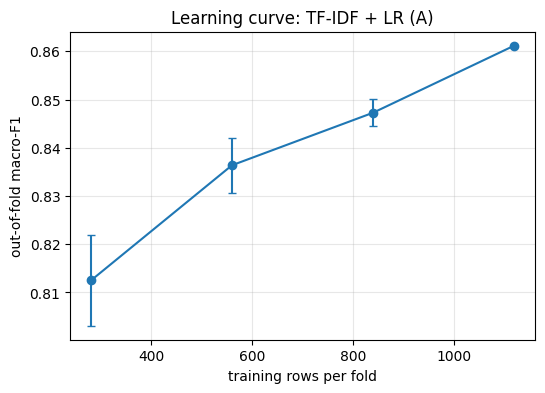

          train_rows   mean     sd
fraction                          
0.25         280.800  0.813  0.009
0.50         560.067  0.836  0.006
0.75         840.267  0.847  0.003
1.00        1120.000  0.861  0.000


In [44]:
def learning_curve(fit_predict, text_col, fractions, repeats, seed=SEED):
    rows = []
    for fraction in fractions:
        for repeat in range(repeats):
            rng = np.random.RandomState(seed + repeat)
            oof = np.zeros((len(train_pool), N_CLASSES))
            sizes = []
            for fold in range(N_FOLDS):
                train_df = train_pool[train_pool["fold"] != fold]
                valid_df = train_pool[train_pool["fold"] == fold]
                groups = train_df["text_key"].unique()
                keep = rng.choice(groups, size=max(1, int(round(fraction * len(groups)))), replace=False)
                subset = train_df[train_df["text_key"].isin(keep)]
                sizes.append(len(subset))
                oof[valid_df.index.to_numpy()] = fit_predict(subset, valid_df, text_col)
            rows.append({"fraction": fraction, "repeat": repeat, "train_rows": float(np.mean(sizes)),
                         "macro_f1": macro_f1(y_train, oof.argmax(axis=1))})
    return pd.DataFrame(rows)


def plot_learning_curve(curve, title):
    summary = curve.groupby("fraction").agg(train_rows=("train_rows", "mean"), mean=("macro_f1", "mean"),
                                            sd=("macro_f1", "std")).fillna(0)
    plt.figure(figsize=(6, 4))
    plt.errorbar(summary["train_rows"], summary["mean"], yerr=summary["sd"], marker="o", capsize=3)
    plt.xlabel("training rows per fold")
    plt.ylabel("out-of-fold macro-F1")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()
    return summary


best_version = max(best_lr, key=lambda version: best_lr[version]["score"])
best_text_col, best_C = TEXT_VERSIONS[best_version], best_lr[best_version]["C"]
curve_lr = learning_curve(lambda tr, va, col: lr_fit_predict(tr, va, col, best_C), best_text_col,
                          LEARNING_CURVE_FRACTIONS, LEARNING_CURVE_REPEATS)
print(f"TF-IDF + LR, text version {best_version}, C = {best_C}")
print(plot_learning_curve(curve_lr, f"Learning curve: TF-IDF + LR ({best_version})").round(3))

## 4. IndoBERT Cross-Validation

Every run fine-tunes the model on four folds and predicts the fifth, for all five folds. The training loop is plain PyTorch: AdamW with linear warmup and decay, class-weighted cross-entropy (weights proportional to inverse class frequency raised to `CLASS_WEIGHT_POWER`), gradient clipping and mixed precision on GPU.

Each epoch stores out-of-fold and test probabilities, so the epoch count can be read from the curves in Stage 5 without retraining. Test probabilities are the average of the five fold models. Finished runs are saved to `results/` and skipped on rerun. Fold models are saved only for the tags listed in `SAVE_MODELS_FOR` (about 0.4 GB per fold model), and a finished run whose models are missing is retrained.

In [57]:
def encode(tokenizer, texts):
    return tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)["input_ids"]


def to_device(batch):
    return {key: value.to(DEVICE) for key, value in batch.items()}


def class_weights(labels):
    counts = np.bincount(labels, minlength=N_CLASSES).astype(float)
    weights = (counts.sum() / (N_CLASSES * np.maximum(counts, 1))) ** CLASS_WEIGHT_POWER
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


@torch.no_grad()
def predict_proba(model, tokenizer, ids):
    model.eval()
    order = np.argsort([len(item) for item in ids])
    out = np.zeros((len(ids), N_CLASSES), dtype=np.float32)
    for start in range(0, len(order), EVAL_BATCH_SIZE):
        chosen = order[start:start + EVAL_BATCH_SIZE]
        batch = to_device(tokenizer.pad({"input_ids": [ids[i] for i in chosen]}, return_tensors="pt"))
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            logits = model(**batch).logits
        out[chosen] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return out


def train_fold(train_df, valid_df, test_df, text_col, model_name, seed):
    seed_everything(seed)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=N_CLASSES).to(DEVICE)
    train_ids = encode(tokenizer, train_df[text_col])
    valid_ids = encode(tokenizer, valid_df[text_col])
    test_ids = encode(tokenizer, test_df[text_col])
    labels = train_df["label_id"].to_numpy()
    y_valid = valid_df["label_id"].to_numpy()

    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights(labels))
    skip_decay = ("bias", "LayerNorm.weight")
    parameters = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in skip_decay)],
         "weight_decay": WEIGHT_DECAY},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in skip_decay)],
         "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(parameters, lr=LEARNING_RATE)
    total_steps = int(np.ceil(len(train_ids) / BATCH_SIZE)) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    rng = np.random.RandomState(seed)

    valid_snapshots, test_snapshots = [], []
    for epoch in range(EPOCHS):
        model.train()
        order = rng.permutation(len(train_ids))
        running, n_batches = 0.0, 0
        for start in range(0, len(order), BATCH_SIZE):
            chosen = order[start:start + BATCH_SIZE]
            batch = to_device(tokenizer.pad({"input_ids": [train_ids[i] for i in chosen]}, return_tensors="pt"))
            target = torch.tensor(labels[chosen], device=DEVICE)
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), target)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
            n_batches += 1
        valid_snapshots.append(predict_proba(model, tokenizer, valid_ids))
        test_snapshots.append(predict_proba(model, tokenizer, test_ids))
        print(f"    epoch {epoch + 1}/{EPOCHS} | train loss {running / n_batches:.4f} | "
              f"valid macro-F1 {macro_f1(y_valid, valid_snapshots[-1].argmax(axis=1)):.3f}")
    return np.stack(valid_snapshots), np.stack(test_snapshots), model, tokenizer


def run_cv(tag, text_col, model_name, seed):
    run_id = f"{tag}_s{seed}"
    oof_path, test_path = RESULTS_DIR / f"oof_{run_id}.npy", RESULTS_DIR / f"test_{run_id}.npy"
    save_models = tag in SAVE_MODELS_FOR
    models_ready = not save_models or all((MODEL_DIR / run_id / f"fold{fold}").exists() for fold in range(N_FOLDS))
    if oof_path.exists() and test_path.exists() and models_ready:
        print(f"{run_id}: loaded from results/")
        return np.load(oof_path), np.load(test_path)

    oof = np.zeros((EPOCHS, len(train_pool), N_CLASSES), dtype=np.float32)
    test_probs = np.zeros((EPOCHS, len(test_set), N_CLASSES), dtype=np.float32)
    for fold in range(N_FOLDS):
        started = time.time()
        print(f"{run_id} | fold {fold + 1}/{N_FOLDS}")
        train_df = train_pool[train_pool["fold"] != fold]
        valid_df = train_pool[train_pool["fold"] == fold]
        valid_probs, fold_test_probs, model, tokenizer = train_fold(
            train_df, valid_df, test_set, text_col, model_name, seed + fold)
        oof[:, valid_df.index.to_numpy(), :] = valid_probs
        test_probs += fold_test_probs / N_FOLDS
        if save_models:
            target = MODEL_DIR / run_id / f"fold{fold}"
            model.save_pretrained(target)
            tokenizer.save_pretrained(target)
        del model
        if USE_AMP:
            torch.cuda.empty_cache()
        print(f"    fold finished in {time.time() - started:.0f}s")
    np.save(oof_path, oof)
    np.save(test_path, test_probs)
    (RESULTS_DIR / f"meta_{run_id}.json").write_text(json.dumps({
        "tag": tag, "text_col": text_col, "model": str(model_name), "seed": seed, "epochs": EPOCHS,
        "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "class_weight_power": CLASS_WEIGHT_POWER}, indent=2))
    return oof, test_probs


def execute_runs():
    for tag, spec in BERT_RUNS.items():
        per_seed = [run_cv(tag, spec["text_col"], spec["model"], seed) for seed in SEEDS]
        runs[f"BERT_{tag}"] = {
            "oof": np.mean([item[0] for item in per_seed], axis=0),
            "test": np.mean([item[1] for item in per_seed], axis=0),
        }
    print("\nruns available:", list(runs))

In [58]:
probe = AutoTokenizer.from_pretrained(MODEL_NAME)
lengths = pd.Series({version: [len(ids) for ids in encode(probe, train_pool[col])]
                     for version, col in TEXT_VERSIONS.items()}).apply(pd.Series).T
share_truncated = (lengths >= MAX_LENGTH).mean()
print("Token length percentiles (training pool)")
print(lengths.quantile([0.5, 0.9, 0.99, 1.0]).T.round(0))
for version, share in share_truncated.items():
    if share > 0.01:
        print(f"FLAG: {share:.1%} of version {version} texts reach MAX_LENGTH = {MAX_LENGTH}")

Token length percentiles (training pool)
   0.50  0.90  0.99   1.00
A   9.0  33.0  81.0  118.0
B   9.0  33.0  78.0  118.0
C   9.0  33.0  78.0  118.0


In [59]:
# EMOJI_WORDS = {"👍": " bagus ", "👎": " jelek ", "🥰": " suka ", "😍": " suka ", "🤬": " marah ", "😡": " marah "}


# def emoji_to_words(text):
#     for symbol, word in EMOJI_WORDS.items():
#         text = text.replace(symbol, word)
#     return " ".join(text.split())


# for frame in (train_pool, test_set):
#     frame["text_emoji"] = frame["text_norm"].map(emoji_to_words)
# BERT_RUNS["D"] = {"text_col": "text_emoji", "model": MODEL_NAME}

In [60]:
execute_runs()

B_s42 | fold 1/5


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/4 | train loss 0.6348 | valid macro-F1 0.859
    epoch 2/4 | train loss 0.1834 | valid macro-F1 0.874
    epoch 3/4 | train loss 0.0624 | valid macro-F1 0.891
    epoch 4/4 | train loss 0.0186 | valid macro-F1 0.902


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (81 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/4 | train loss 0.6089 | valid macro-F1 0.854
    epoch 2/4 | train loss 0.1796 | valid macro-F1 0.887
    epoch 3/4 | train loss 0.0570 | valid macro-F1 0.894
    epoch 4/4 | train loss 0.0206 | valid macro-F1 0.904


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    fold finished in 34s

runs available: ['LR_A', 'LR_B', 'LR_C', 'BERT_B']


### IndoBERT learning curve (optional)

The same subsampling as in Stage 3, with IndoBERT retrained for every fraction, fold and repeat. This is the most expensive cell of the notebook, so it is controlled by `LEARNING_CURVE_BERT`.

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/4 | train loss 0.9114 | valid macro-F1 0.757
    epoch 2/4 | train loss 0.4305 | valid macro-F1 0.882
    epoch 3/4 | train loss 0.2030 | valid macro-F1 0.845
    epoch 4/4 | train loss 0.1057 | valid macro-F1 0.858


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (230 outputs left out)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/4 | train loss 0.5948 | valid macro-F1 0.882
    epoch 2/4 | train loss 0.1931 | valid macro-F1 0.917
    epoch 3/4 | train loss 0.0590 | valid macro-F1 0.890
    epoch 4/4 | train loss 0.0197 | valid macro-F1 0.893


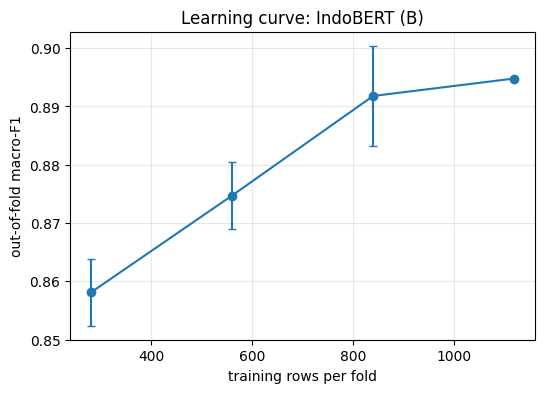

          train_rows   mean     sd
fraction                          
0.25         280.800  0.858  0.006
0.50         560.067  0.875  0.006
0.75         840.267  0.892  0.009
1.00        1120.000  0.895  0.000


In [49]:
def bert_fit_predict(train_df, valid_df, text_col):
    valid_probs, _, model, _ = train_fold(train_df, valid_df, valid_df.iloc[:1], text_col, MODEL_NAME, SEED)
    del model
    return valid_probs[min(SELECTED_EPOCH, EPOCHS) - 1]


if LEARNING_CURVE_BERT:
    curve_bert = learning_curve(bert_fit_predict, TEXT_VERSIONS["B"], LEARNING_CURVE_FRACTIONS,
                                LEARNING_CURVE_REPEATS)
    print(plot_learning_curve(curve_bert, "Learning curve: IndoBERT (B)").round(3))
else:
    print("LEARNING_CURVE_BERT is False: skipped")

## 5. Comparison

All numbers in this stage come from pooled out-of-fold predictions. The epoch curves show where each run peaks; `SELECTED_EPOCH` in the configuration decides which snapshot is compared. Paired differences use the same bootstrap resamples for both runs, so they are more sensitive than comparing two separate intervals.

The label audit lists reviews where the out-of-fold model is highly confident in a class different from the label. These are candidates for relabeling, not errors by default.

Out-of-fold macro-F1 by epoch
       BERT_B
epoch        
1       0.863
2       0.890
3       0.899
4       0.897


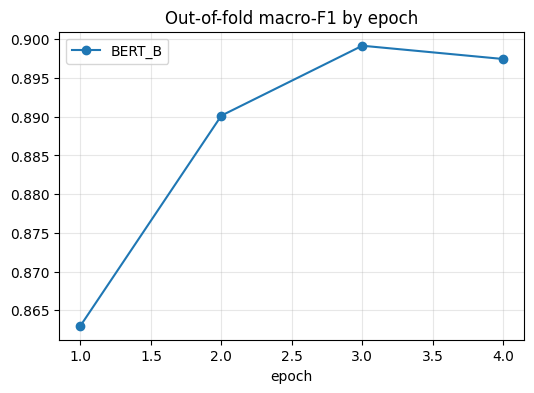

In [62]:
def epoch_curves():
    rows = {}
    for name, run in runs.items():
        if run["oof"].shape[0] > 1:
            rows[name] = [macro_f1(y_train, snap.argmax(axis=1)) for snap in run["oof"]]
    return pd.DataFrame(rows, index=range(1, EPOCHS + 1)).rename_axis("epoch")


curves = epoch_curves()
if len(curves):
    print("Out-of-fold macro-F1 by epoch")
    print(curves.round(3))
    curves.plot(marker="o", figsize=(6, 4), title="Out-of-fold macro-F1 by epoch")
    plt.grid(alpha=0.3)
    plt.show()

In [63]:
oof_pred = {name: snapshot(name, "oof").argmax(axis=1) for name in runs}
boot = group_bootstrap(y_train, oof_pred, train_pool["text_key"])

table = pd.DataFrame([summarize(y_train, snapshot(name, "oof"), name) for name in runs]).set_index("run")
table["ci_low"] = boot.quantile(0.025)
table["ci_high"] = boot.quantile(0.975)
not_uncertain = (train_pool["uncertain"] == 0).to_numpy()
table["macro_f1_certain_only"] = [macro_f1(y_train[not_uncertain], oof_pred[name][not_uncertain]) for name in table.index]
print(f"Pooled out-of-fold results (epoch {SELECTED_EPOCH} for IndoBERT runs)")
print(table.round(3).sort_values("macro_f1", ascending=False))

per_app = pd.DataFrame({name: macro_f1_by(train_pool, oof_pred[name], "app_name") for name in runs})
print("\nMacro-F1 by app")
print(per_app.round(3))

best_run = table["macro_f1"].idxmax()
reference = "BERT_A" if "BERT_A" in runs else best_run
paired = []
for name in runs:
    if name != reference:
        difference = boot[name] - boot[reference]
        low, high = difference.quantile(0.025), difference.quantile(0.975)
        paired.append({"run": name, "reference": reference, "mean_diff": difference.mean(),
                       "ci_low": low, "ci_high": high, "ci_excludes_zero": bool(low > 0 or high < 0)})
print("\nPaired macro-F1 differences versus", reference)
print(pd.DataFrame(paired).round(3).to_string(index=False))
print("\nbest run by pooled macro-F1:", best_run)

Pooled out-of-fold results (epoch 4 for IndoBERT runs)
           n  accuracy  macro_f1  f1_negative  f1_neutral  f1_positive  \
run                                                                      
BERT_B  1400     0.913     0.897        0.937       0.830        0.926   
LR_A    1400     0.879     0.861        0.905       0.781        0.898   
LR_B    1400     0.879     0.861        0.904       0.778        0.900   
LR_C    1400     0.879     0.859        0.910       0.770        0.898   

        ci_low  ci_high  macro_f1_certain_only  
run                                             
BERT_B   0.879    0.915                  0.948  
LR_A     0.840    0.880                  0.910  
LR_B     0.840    0.879                  0.908  
LR_C     0.838    0.878                  0.910  

Macro-F1 by app
                   LR_A   LR_B   LR_C  BERT_B
BRImo             0.887  0.887  0.882   0.899
Livin_by_Mandiri  0.844  0.847  0.848   0.899
myBCA             0.830  0.830  0.827   0.895
wondr

In [64]:
best_probs = snapshot(best_run, "oof")
best_pred = best_probs.argmax(axis=1)
matrix = pd.DataFrame(confusion_matrix(y_train, best_pred, labels=list(LABEL_NAMES)),
                      index=[f"true_{name}" for name in LABEL_NAMES.values()],
                      columns=[f"pred_{name}" for name in LABEL_NAMES.values()])
print(f"Confusion matrix, {best_run}")
print(matrix)

confidence = best_probs.max(axis=1)
suspect_mask = (best_pred != y_train) & (confidence >= AUDIT_MIN_CONFIDENCE)
audit = train_pool.loc[suspect_mask, ["sample_id", "app_name", "uncertain", "label_id", "text_raw"]].copy()
audit["model_label_id"] = best_pred[suspect_mask]
audit["model_confidence"] = confidence[suspect_mask]
audit = audit.sort_values("model_confidence", ascending=False)
audit.to_csv(RESULTS_DIR / "label_audit.csv", index=False, encoding="utf-8-sig")

print(f"\nLabel audit: {len(audit)} rows where the model disagrees with the label at confidence >= {AUDIT_MIN_CONFIDENCE}")
print(f"  of which already marked uncertain: {int(audit['uncertain'].sum())}")
shown = audit.head(25).assign(text_raw=lambda frame: frame["text_raw"].str.slice(0, 80))
print(shown[["sample_id", "label_id", "model_label_id", "model_confidence", "text_raw"]].round(3).to_string(index=False))

Confusion matrix, BERT_B
               pred_negative  pred_neutral  pred_positive
true_negative            584            28             19
true_neutral              17           215             22
true_positive             15            21            479

Label audit: 63 rows where the model disagrees with the label at confidence >= 0.85
  of which already marked uncertain: 39
sample_id  label_id  model_label_id  model_confidence                                                                         text_raw
   S00050         0               2             0.999                                                                               👎👎
   S00867         0               2             0.998                                        sangat membantu, ya kurangi biaya operasi
   T00001         2               1             0.998                                                baru coba uda kasih bintang 5 dlu
   S00594         1               2             0.998                         

In [65]:
only_batch01 = train_pool["selection_source"].eq("batch01").to_numpy()
print("Original batch01 rows only (same rows as the first round)")
print(pd.DataFrame([summarize(y_train[only_batch01], snapshot(name, "oof")[only_batch01], name)
                    for name in runs]).set_index("run").round(3))

Original batch01 rows only (same rows as the first round)
           n  accuracy  macro_f1  f1_negative  f1_neutral  f1_positive
run                                                                   
LR_A    1000     0.922     0.804        0.943       0.525        0.943
LR_B    1000     0.922     0.804        0.943       0.525        0.943
LR_C    1000     0.920     0.794        0.946       0.495        0.940
BERT_B  1000     0.956     0.865        0.969       0.658        0.967


In [55]:
# mask = train_pool["selection_source"].isin(["batch01", "random"]).to_numpy()
# pred = oof_pred["BERT_B"][mask]
# print(f"neutral share: true {(y_train[mask] == 1).mean():.3f} | predicted {(pred == 1).mean():.3f}")

neutral share: true 0.044 | predicted 0.035


## 6. Test Evaluation

The test set is evaluated once, for the run named in `FINAL_RUN`. Test probabilities are the average of the five fold models at the selected epoch. The report adds three views: all rows, rows whose text does not occur in the training pool (a stricter generalization check), and per app. The neutral class has few test rows, so its F1 is printed together with its support.

In [67]:
if FINAL_RUN is None:
    print("FINAL_RUN is not set: test evaluation skipped")
elif FINAL_RUN not in runs:
    print(f"FINAL_RUN '{FINAL_RUN}' is not among the available runs: {list(runs)}")
else:
    test_probs = snapshot(FINAL_RUN, "test")
    test_pred = test_probs.argmax(axis=1)
    unseen = ~test_set["text_shared_across_roles"].to_numpy()
    certain = (test_set["uncertain"] == 0).to_numpy()

    views = {"all test rows": np.ones(len(test_set), dtype=bool),
             "text not in training pool": unseen,
             "certain labels only": certain}
    rows = []
    for view, mask in views.items():
        boot_test = group_bootstrap(y_test[mask], {"run": test_pred[mask]}, test_set.loc[mask, "text_key"])["run"]
        row = summarize(y_test[mask], test_probs[mask], view)
        row["ci_low"], row["ci_high"] = boot_test.quantile(0.025), boot_test.quantile(0.975)
        rows.append(row)
    print(f"Test results for {FINAL_RUN} (epoch {SELECTED_EPOCH})")
    print(pd.DataFrame(rows).set_index("run").round(3))

    print("\nSupport per class (test):", pd.Series(y_test).map(LABEL_NAMES).value_counts().to_dict())
    if (np.bincount(y_test, minlength=N_CLASSES) < 30).any():
        print("FLAG: a class has fewer than 30 test rows, its F1 is a rough estimate")
    print("\nMacro-F1 by app (test)")
    print(pd.Series(macro_f1_by(test_set, test_pred, "app_name")).round(3))
    print("\nConfusion matrix (test)")
    print(pd.DataFrame(confusion_matrix(y_test, test_pred, labels=list(LABEL_NAMES)),
                       index=[f"true_{name}" for name in LABEL_NAMES.values()],
                       columns=[f"pred_{name}" for name in LABEL_NAMES.values()]))

Test results for BERT_B (epoch 4)
                             n  accuracy  macro_f1  f1_negative  f1_neutral  \
run                                                                           
all test rows              500     0.974     0.944        0.978       0.873   
text not in training pool  375     0.965     0.826        0.978       0.533   
certain labels only        472     0.989     0.980        0.989       0.958   

                           f1_positive  ci_low  ci_high  
run                                                      
all test rows                    0.982   0.820    0.979  
text not in training pool        0.965   0.695    0.923  
certain labels only              0.993   0.865    0.998  

Support per class (test): {'negative': 254, 'positive': 217, 'neutral': 29}
FLAG: a class has fewer than 30 test rows, its F1 is a rough estimate

Macro-F1 by app (test)
BRImo               0.970
Livin_by_Mandiri    0.896
myBCA               0.912
wondr_by_BNI        1.000
dtype

## 7. Continued Pretraining (optional)

Masked-language-model training on unlabeled reviews adapts IndoBERT to the vocabulary of mobile banking reviews (abbreviations, slang, product terms). The corpus is the unique normalized texts of the whole population, excluding every text that occurs in the test set. The adapted model is saved to `models/indobert_dapt` and added as run `B_dapt`, which is compared with run `B` on identical folds.

In [23]:
DAPT_DIR = MODEL_DIR / "indobert_dapt"


def continued_pretraining():
    if (DAPT_DIR / "config.json").exists():
        print("adapted model exists: skipped")
        return
    population = pd.read_csv(PROCESSED_DIR / "population_normalized.csv", encoding="utf-8-sig",
                             usecols=["text_norm", "text_key"])
    corpus = population[~population["text_key"].isin(set(test_set["text_key"]))]
    corpus = corpus.drop_duplicates("text_key")["text_norm"].tolist()
    print(f"corpus: {len(corpus)} unique texts, test texts excluded")

    seed_everything(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME).to(DEVICE)
    collator = DataCollatorForLanguageModeling(tokenizer, mlm=True, mlm_probability=DAPT_MLM_PROBABILITY)
    ids = tokenizer(corpus, truncation=True, max_length=DAPT_MAX_LENGTH)["input_ids"]

    optimizer = torch.optim.AdamW(model.parameters(), lr=DAPT_LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = int(np.ceil(len(ids) / DAPT_BATCH_SIZE)) * DAPT_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    rng = np.random.RandomState(SEED)

    step = 0
    for epoch in range(DAPT_EPOCHS):
        model.train()
        order = rng.permutation(len(ids))
        running, n_batches = 0.0, 0
        for start in range(0, len(order), DAPT_BATCH_SIZE):
            chosen = order[start:start + DAPT_BATCH_SIZE]
            batch = to_device(collator([{"input_ids": ids[i]} for i in chosen]))
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
            n_batches += 1
            step += 1
            if step % 200 == 0:
                print(f"  step {step}/{total_steps} | MLM loss {running / n_batches:.4f}")
        print(f"epoch {epoch + 1}/{DAPT_EPOCHS} | MLM loss {running / n_batches:.4f}")
    model.save_pretrained(DAPT_DIR)
    tokenizer.save_pretrained(DAPT_DIR)
    print("saved", DAPT_DIR)


if RUN_DAPT:
    continued_pretraining()
    BERT_RUNS["B_dapt"] = {"text_col": "text_norm", "model": str(DAPT_DIR)}
    execute_runs()
else:
    print("RUN_DAPT is False: continued pretraining skipped")

corpus: 81874 unique texts, test texts excluded


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

... (23 outputs left out)

    epoch 4/4 | train loss 0.0301 | valid macro-F1 0.819
    fold finished in 23s
B_dapt_s42 | fold 5/5


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: /content/drive/MyDrive/mbanking_sentiment/models/indobert_dapt
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on

    epoch 1/4 | train loss 0.7168 | valid macro-F1 0.738
    epoch 2/4 | train loss 0.2125 | valid macro-F1 0.840
    epoch 3/4 | train loss 0.0616 | valid macro-F1 0.887
    epoch 4/4 | train loss 0.0124 | valid macro-F1 0.858
    fold finished in 23s

runs available: ['LR_A', 'LR_B', 'LR_C', 'BERT_A', 'BERT_B', 'BERT_C', 'BERT_D', 'BERT_B_dapt']


## 8. Population Prediction

The chosen run's fold models (saved for the tags listed in `SAVE_MODELS_FOR`) are averaged to predict every review in the population. The output keeps the review metadata and adds the predicted class, the three class probabilities and the maximum probability, so low-confidence predictions can be examined or excluded in the final analysis. Predictions come from the last epoch, because only final models are saved.

In [68]:
POPULATION_COLUMNS = [
    "review_id", "app_name", "app_id", "review_date", "review_month", "review_created_version",
    "app_version", "rating", "thumbs_up", "text_raw", "text_norm", "text_norm_slang", "text_key",
    "is_short", "text_freq",
]


def predict_population(run_tag):
    spec = BERT_RUNS[run_tag]
    if SELECTED_EPOCH != EPOCHS:
        print(f"FLAG: SELECTED_EPOCH ({SELECTED_EPOCH}) differs from EPOCHS ({EPOCHS}); saved models are from epoch {EPOCHS}")
    population = pd.read_csv(PROCESSED_DIR / "population_normalized.csv", encoding="utf-8-sig",
                             parse_dates=["review_date"], usecols=POPULATION_COLUMNS,
                             dtype={"review_created_version": str, "app_version": str})
    total, n_models = np.zeros((len(population), N_CLASSES)), 0
    for seed in SEEDS:
        for fold in range(N_FOLDS):
            path = MODEL_DIR / f"{run_tag}_s{seed}" / f"fold{fold}"
            if not path.exists():
                raise FileNotFoundError(f"{path} not found; add '{run_tag}' to SAVE_MODELS_FOR and rerun Stage 4")
            tokenizer = AutoTokenizer.from_pretrained(path)
            model = AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE)
            total += predict_proba(model, tokenizer, encode(tokenizer, population[spec["text_col"]]))
            n_models += 1
            del model
            print(f"  model {n_models} done")
    probs = total / n_models
    population["pred_label_id"] = probs.argmax(axis=1)
    population["pred_label"] = population["pred_label_id"].map(LABEL_NAMES)
    for class_id, class_name in LABEL_NAMES.items():
        population[f"p_{class_name}"] = probs[:, class_id]
    population["max_prob"] = probs.max(axis=1)
    population.to_csv(PROCESSED_DIR / "population_predictions.csv", index=False, encoding="utf-8-sig")

    print(f"\nsaved population_predictions.csv ({len(population)} rows)")
    print("\nPredicted class share by app")
    print(pd.crosstab(population["app_name"], population["pred_label"], normalize="index").round(3))
    print(f"\nshare of predictions with max_prob < 0.6: {(population['max_prob'] < 0.6).mean():.1%}")
    return population


FINAL_PREDICTION_TAG = "B"
if FINAL_PREDICTION_TAG is None:
    print("FINAL_PREDICTION_TAG is not set: population prediction skipped")
else:
    population_predictions = predict_population(FINAL_PREDICTION_TAG)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  model 1 done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  model 2 done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  model 3 done


... (20 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  model 14 done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  model 15 done

saved population_predictions.csv (134910 rows)

Predicted class share by app
pred_label        negative  neutral  positive
app_name                                     
BRImo                0.303    0.057     0.640
Livin_by_Mandiri     0.701    0.041     0.258
myBCA                0.646    0.060     0.294
wondr_by_BNI         0.270    0.068     0.663

share of predictions with max_prob < 0.6: 0.8%


In [18]:
print(probe.tokenize("👍 👎 🥰 🤬"))

['[UNK]', '[UNK]', '[UNK]', '[UNK]']


### 9. Sembilan

In [35]:
import re

BATCH2_ID = "batch02"
BATCH2_PER_APP = 100
BATCH2_NEUTRAL_PER_APP = 40
BATCH2_UNCERTAIN_PER_APP = 40
BATCH2_MAX_COPIES = 2

LABEL_DIR = BASE_DIR / "data" / "labeling"
KEY_PATH_2 = LABEL_DIR / f"sample_key_{BATCH2_ID}.csv"
SHEET_PATH_2 = LABEL_DIR / f"labeling_sheet_{BATCH2_ID}.csv"
EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F]")
OK_PATTERN = r"(ok|oke|okee|okey|okei|okay|okok|ok lah|oke lah)"
KEY_COLUMNS = [
    "sample_id", "role", "review_id", "app_name", "review_date", "rating", "thumbs_up",
    "review_created_version", "app_version", "text_raw", "text_norm", "text_norm_slang",
    "text_key", "text_freq", "n_chars", "n_words", "has_emoji", "is_emoji_only", "is_short",
    "text_shared_across_roles",
]


def pick(pool, order_column, n, taken_keys, skip_ok):
    ordered = pool.sort_values(order_column, ascending=False) if order_column else pool.sample(frac=1, random_state=SEED)
    ordered = ordered[~ordered["text_key"].isin(taken_keys)]
    if skip_ok:
        ordered = ordered[~ordered["text_key"].str.fullmatch(OK_PATTERN)]
    return ordered.drop_duplicates("text_key").head(n)


def build_batch2():
    predictions = pd.read_csv(PROCESSED_DIR / "population_predictions.csv", encoding="utf-8-sig",
                              parse_dates=["review_date"],
                              dtype={"review_created_version": str, "app_version": str})
    earlier_paths = [path for path in LABEL_DIR.glob("sample_key_*.csv") if path != KEY_PATH_2]
    earlier = pd.concat([pd.read_csv(path, encoding="utf-8-sig", usecols=["review_id", "text_key", "role"])
                         for path in earlier_paths], ignore_index=True)
    test_keys = set(earlier.loc[earlier["role"] == "test", "text_key"])
    copies_used = earlier["text_key"].value_counts()

    probs = predictions[[f"p_{name}" for name in LABEL_NAMES.values()]].to_numpy()
    predictions["entropy"] = -(probs * np.log(np.clip(probs, 1e-12, None))).sum(axis=1)
    capacity = BATCH2_MAX_COPIES - predictions["text_key"].map(copies_used).fillna(0)
    candidates = predictions[~predictions["review_id"].isin(set(earlier["review_id"]))
                             & ~predictions["text_key"].isin(test_keys) & (capacity > 0)]
    print(f"candidates after exclusions: {len(candidates)} of {len(predictions)}")

    n_random = BATCH2_PER_APP - BATCH2_NEUTRAL_PER_APP - BATCH2_UNCERTAIN_PER_APP
    plan = [("high_neutral", "p_neutral", BATCH2_NEUTRAL_PER_APP, True),
            ("high_entropy", "entropy", BATCH2_UNCERTAIN_PER_APP, True),
            ("random", None, n_random, False)]
    chosen_parts = []
    for app_name, pool in candidates.groupby("app_name"):
        taken = set()
        for source, column, n, skip_ok in plan:
            chosen = pick(pool, column, n, taken, skip_ok)
            taken |= set(chosen["text_key"])
            if len(chosen) < n:
                print(f"FLAG: {app_name} {source}: only {len(chosen)} of {n} candidates available")
            chosen_parts.append(chosen.assign(selection_source=source))

    batch = pd.concat(chosen_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    batch.insert(0, "sample_id", [f"T{i + 1:05d}" for i in range(len(batch))])
    batch["role"] = "train_pool"
    batch["text_shared_across_roles"] = False
    batch["n_chars"] = batch["text_norm"].str.len()
    batch["n_words"] = batch["text_norm"].str.split().str.len()
    batch["has_emoji"] = batch["text_norm"].str.contains(EMOJI_RE)
    batch["is_emoji_only"] = batch["has_emoji"] & ~batch["text_norm"].str.contains(r"[^\W_]", regex=True)

    print("\nSelected rows by app and source")
    print(pd.crosstab(batch["app_name"], batch["selection_source"], margins=True))
    print("\nPredicted class by source (share)")
    print(pd.crosstab(batch["selection_source"], batch["pred_label"], normalize="index").round(3))
    print("\nMean p_neutral by source:", batch.groupby("selection_source")["p_neutral"].mean().round(3).to_dict())
    print(f"share of short texts: {batch['is_short'].mean():.1%} | unique texts: {batch['text_key'].nunique()} of {len(batch)}")

    batch[KEY_COLUMNS + ["selection_source"]].to_csv(KEY_PATH_2, index=False, encoding="utf-8-sig")
    batch[["sample_id", "app_name", "text_raw"]].assign(label_id="", uncertain="").to_csv(
        SHEET_PATH_2, index=False, encoding="utf-8-sig")
    print(f"\nsaved {KEY_PATH_2.name} and {SHEET_PATH_2.name} ({len(batch)} rows)")


if KEY_PATH_2.exists():
    print(f"{KEY_PATH_2.name} exists: not overwritten")
else:
    build_batch2()

candidates after exclusions: 98607 of 134910

Selected rows by app and source
selection_source  high_entropy  high_neutral  random  All
app_name                                                 
BRImo                       40            40      20  100
Livin_by_Mandiri            40            40      20  100
myBCA                       40            40      20  100
wondr_by_BNI                40            40      20  100
All                        160           160      80  400

Predicted class by source (share)
pred_label        negative  neutral  positive
selection_source                             
high_entropy         0.312    0.275     0.412
high_neutral         0.000    1.000     0.000
random               0.625    0.050     0.325

Mean p_neutral by source: {'high_entropy': 0.31, 'high_neutral': 0.99, 'random': 0.044}
share of short texts: 0.0% | unique texts: 371 of 400

saved sample_key_batch02.csv and labeling_sheet_batch02.csv (400 rows)
